Compare results before and after tuning by manually computing and visualizing performance improvements across multiple models, ensuring a thorough analysis of convergence and generalization.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from itertools import product
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

df = pd.read_csv("heart_disease_train.csv")

features = ["age", "trestbps", "chol", "thalach", "oldpeak"]
target = "target"

df = df[features + [target]].copy()

for col in features + [target]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna()

X = df[features].to_numpy(dtype=float)
y = df[target].to_numpy(dtype=int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 63
Testing samples: 16


In [2]:
def make_model(name, params=None):
    params = params or {}

    if name == "Logistic Regression":
        return make_pipeline(
            StandardScaler(),
            LogisticRegression(
                max_iter=1000, class_weight="balanced", **params
            )
        )

    if name == "Decision Tree":
        return DecisionTreeClassifier(
            class_weight="balanced", random_state=42, **params
        )

    if name == "Random Forest":
        return RandomForestClassifier(
            n_estimators=100, class_weight="balanced",
            random_state=42, **params
        )

    if name == "SVM":
        return make_pipeline(
            StandardScaler(),
            SVC(class_weight="balanced", random_state=42, **params)
        )

    if name == "KNN":
        return make_pipeline(
            StandardScaler(),
            KNeighborsClassifier(**params)
        )

    raise ValueError("Unknown model: " + name)


baseline_params = {
    "Logistic Regression": {},
    "Decision Tree": {},
    "Random Forest": {},
    "SVM": {},
    "KNN": {}
}

param_grids = {
    "Logistic Regression": {
        "C": [0.1, 1, 10]
    },
    "Decision Tree": {
        "max_depth": [3, 5, None],
        "min_samples_leaf": [1, 5]
    },
    "Random Forest": {
        "max_depth": [5, None],
        "min_samples_leaf": [1, 3]
    },
    "SVM": {
        "C": [0.1, 1, 10],
        "kernel": ["linear", "rbf"]
    },
    "KNN": {
        "n_neighbors": [3, 5, 7],
        "weights": ["uniform", "distance"]
    }
}

In [3]:
def manual_metrics(y_true, y_pred):
    tp = np.sum((y_true == 1) & (y_pred == 1))
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))

    accuracy = (tp + tn) / max(tp + tn + fp + fn, 1)
    precision = tp / max(tp + fp, 1)
    recall = tp / max(tp + fn, 1)
    f1 = 2 * precision * recall / max(precision + recall, 1e-12)

    return {
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    }


cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [4]:
baseline_models = {}
tuned_params = {}
tuning_history = {}
all_search_results = []

for name in param_grids:
    print("Processing:", name)

    # Evaluate baseline
    baseline_model = make_model(name, baseline_params[name])
    baseline_model.fit(X_train, y_train)
    baseline_models[name] = baseline_model

    # Build combinations for manual search
    grid = param_grids[name]
    keys = list(grid.keys())
    combinations = [
        dict(zip(keys, values))
        for values in product(*grid.values())
    ]

    scores = []

    # Manually perform cross-validation for each combination
    for params in combinations:
        fold_scores = []

        for train_idx, val_idx in cv.split(X_train, y_train):
            model = make_model(name, params)
            model.fit(X_train[train_idx], y_train[train_idx])

            pred = model.predict(X_train[val_idx])
            metrics = manual_metrics(y_train[val_idx], pred)
            fold_scores.append(metrics["F1 Score"])

        mean_score = float(np.mean(fold_scores))
        scores.append(mean_score)

        all_search_results.append({
            "Model": name,
            "Parameters": str(params),
            "Mean CV F1": mean_score
        })

    # Save best parameters and convergence history
    best_index = int(np.argmax(scores))
    tuned_params[name] = combinations[best_index]

    tuning_history[name] = np.maximum.accumulate(scores)

    print("Best parameters:", tuned_params[name])
    print("Baseline CV F1:", round(
        np.mean([
            manual_metrics(
                y_train[val_idx],
                make_model(name, baseline_params[name])
                .fit(X_train[train_idx], y_train[train_idx])
                .predict(X_train[val_idx])
            )["F1 Score"]
            for train_idx, val_idx in cv.split(X_train, y_train)
        ]), 4
    ))
    print("Best tuned CV F1:", round(scores[best_index], 4))

Processing: Logistic Regression
Best parameters: {'C': 0.1}
Baseline CV F1: 0.8452
Best tuned CV F1: 0.8452
Processing: Decision Tree
Best parameters: {'max_depth': 3, 'min_samples_leaf': 1}
Baseline CV F1: 0.8899
Best tuned CV F1: 0.8899
Processing: Random Forest
Best parameters: {'max_depth': 5, 'min_samples_leaf': 1}
Baseline CV F1: 0.8889
Best tuned CV F1: 0.8889
Processing: SVM
Best parameters: {'C': 10, 'kernel': 'rbf'}
Baseline CV F1: 0.8946
Best tuned CV F1: 0.9208
Processing: KNN
Best parameters: {'n_neighbors': 3, 'weights': 'uniform'}
Baseline CV F1: 0.8908
Best tuned CV F1: 0.8908


In [5]:
comparison = []
final_models = {}

for name in param_grids:
    baseline_model = make_model(name, baseline_params[name])
    tuned_model = make_model(name, tuned_params[name])

    baseline_model.fit(X_train, y_train)
    tuned_model.fit(X_train, y_train)

    final_models[name] = tuned_model

    for stage, model in [
        ("Before Tuning", baseline_model),
        ("After Tuning", tuned_model)
    ]:
        pred = model.predict(X_test)
        metrics = manual_metrics(y_test, pred)

        comparison.append({
            "Model": name,
            "Stage": stage,
            **metrics
        })

comparison_df = pd.DataFrame(comparison)

print(comparison_df.round(4).to_string(index=False))

              Model         Stage  Accuracy  Precision  Recall  F1 Score
Logistic Regression Before Tuning    0.6875     0.7692  0.8333    0.8000
Logistic Regression  After Tuning    0.6875     0.7692  0.8333    0.8000
      Decision Tree Before Tuning    0.7500     0.8333  0.8333    0.8333
      Decision Tree  After Tuning    0.6875     0.8182  0.7500    0.7826
      Random Forest Before Tuning    0.7500     0.8333  0.8333    0.8333
      Random Forest  After Tuning    0.7500     0.8333  0.8333    0.8333
                SVM Before Tuning    0.7500     0.8333  0.8333    0.8333
                SVM  After Tuning    0.6875     0.7692  0.8333    0.8000
                KNN Before Tuning    0.6875     0.7333  0.9167    0.8148
                KNN  After Tuning    0.6250     0.7143  0.8333    0.7692


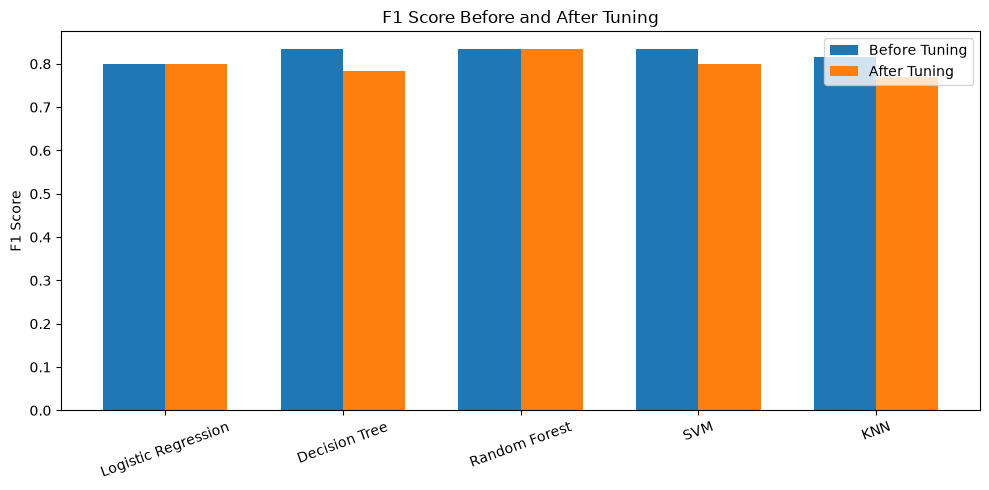

F1-score improvement (positive means better):
Logistic Regression : 0.0
Decision Tree : -0.0507
Random Forest : 0.0
SVM : -0.0333
KNN : -0.0456


In [6]:
metric = "F1 Score"

before = comparison_df[
    comparison_df["Stage"] == "Before Tuning"
].set_index("Model")

after = comparison_df[
    comparison_df["Stage"] == "After Tuning"
].set_index("Model")

x = np.arange(len(before))
width = 0.35

plt.figure(figsize=(10, 5))
plt.bar(x - width / 2, before.loc[after.index, metric], width,
        label="Before Tuning")
plt.bar(x + width / 2, after[metric], width,
        label="After Tuning")

plt.xticks(x, after.index, rotation=20)
plt.ylabel("F1 Score")
plt.title("F1 Score Before and After Tuning")
plt.legend()
plt.tight_layout()
plt.show()

improvements = after[metric] - before.loc[after.index, metric]

print("F1-score improvement (positive means better):")
for name, value in improvements.items():
    print(name, ":", round(value, 4))

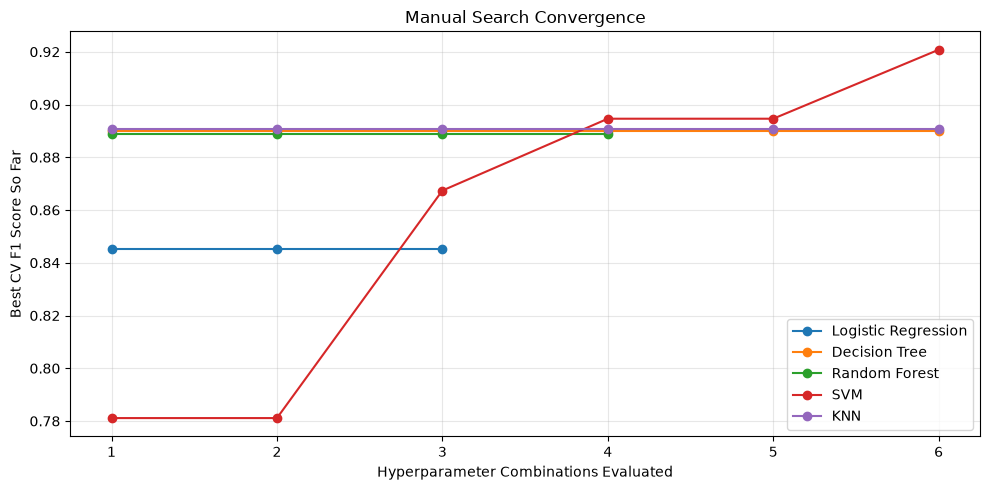

In [7]:
plt.figure(figsize=(10, 5))

for name, history in tuning_history.items():
    plt.plot(
        range(1, len(history) + 1),
        history,
        marker="o",
        label=name
    )

plt.xlabel("Hyperparameter Combinations Evaluated")
plt.ylabel("Best CV F1 Score So Far")
plt.title("Manual Search Convergence")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

              Model  Training F1  Test F1  Generalization Gap
Logistic Regression       0.8182   0.8000              0.0182
      Decision Tree       0.9796   0.7826              0.1970
      Random Forest       1.0000   0.8333              0.1667
                SVM       0.9792   0.8000              0.1792
                KNN       0.9608   0.7692              0.1916


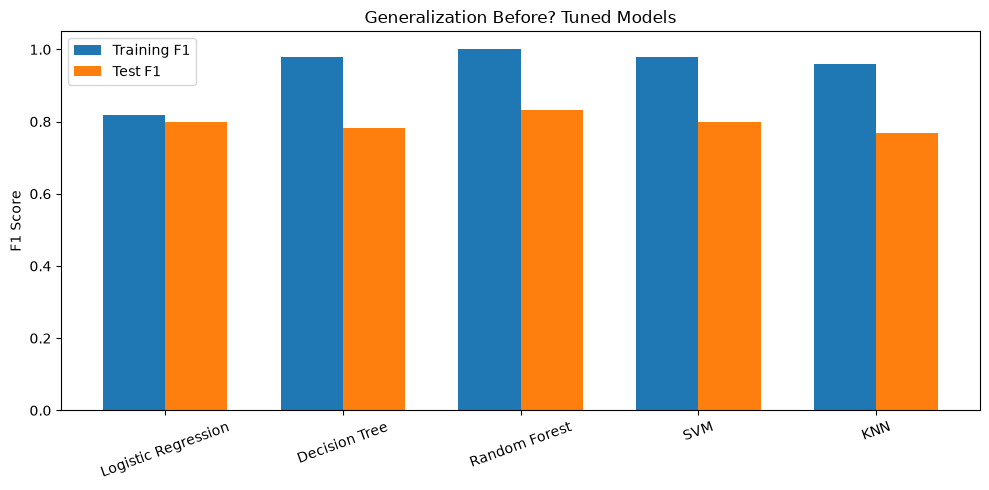

In [8]:
generalization = []

for name in param_grids:
    model = final_models[name]

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    train_f1 = manual_metrics(y_train, train_pred)["F1 Score"]
    test_f1 = manual_metrics(y_test, test_pred)["F1 Score"]

    generalization.append({
        "Model": name,
        "Training F1": train_f1,
        "Test F1": test_f1,
        "Generalization Gap": train_f1 - test_f1
    })

generalization_df = pd.DataFrame(generalization)

print(generalization_df.round(4).to_string(index=False))

plt.figure(figsize=(10, 5))
x = np.arange(len(generalization_df))
width = 0.35

plt.bar(x - width / 2, generalization_df["Training F1"],
        width, label="Training F1")
plt.bar(x + width / 2, generalization_df["Test F1"],
        width, label="Test F1")

plt.xticks(x, generalization_df["Model"], rotation=20)
plt.ylabel("F1 Score")
plt.title("Generalization Before? Tuned Models")
plt.legend()
plt.tight_layout()
plt.show()

In [9]:
summary = comparison_df.pivot(
    index="Model", columns="Stage", values="F1 Score"
)

summary["F1 Improvement"] = (
    summary["After Tuning"] - summary["Before Tuning"]
)

summary = summary.sort_values("F1 Improvement", ascending=False)

print("Final comparison:")
print(summary.round(4).to_string())

best_model_name = summary["After Tuning"].idxmax()
print("\nBest tuned model by test F1:", best_model_name)
print("Best tuned test F1:",
      round(summary.loc[best_model_name, "After Tuning"], 4))

Final comparison:
Stage                After Tuning  Before Tuning  F1 Improvement
Model                                                           
Logistic Regression        0.8000         0.8000          0.0000
Random Forest              0.8333         0.8333          0.0000
SVM                        0.8000         0.8333         -0.0333
KNN                        0.7692         0.8148         -0.0456
Decision Tree              0.7826         0.8333         -0.0507

Best tuned model by test F1: Random Forest
Best tuned test F1: 0.8333
